# Barnstable and Long-Run Risk

**FINM 36700 · Homework 3 · Group 22**
Lucas Albín Lazcano, Avi Rastogi, Mengting Wang, and Yihan Kong

# 2. Estimating Underperformance

### Data

Use the returns on the S&P 500 ($r^m$) and 1-month T-bills ($r^f$) provided in `data/barnstable_analysis_data.xlsx` in the course Box folder.

* Monthly data covers January 1926 through December 2025.
* Stock and T-bill observations are aligned by calendar month. Both series cover all 1,200 months.

Barnstable's estimates of mean and volatility are based on the subsample of 1965 to 1999.

* We consider this subsample, as well as 2000-2025, as well as the full sample of 1926-2025.

### Notation

* $r$ = level return rates
* $R$ = cumulative return factor
* $\texttt{r}$ = log return rates

$$R \equiv 1+r$$

$$\texttt{r} \equiv \ln(1+r) = \ln(R)$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy.stats import norm

data = pd.read_excel("barnstable_analysis_data.xlsx", sheet_name="data").set_index("date")
data.head()

,SPX,TB1M
date,,
1926-01-30,-0.001783,0.003061
1926-02-27,-0.033297,0.002612
1926-03-31,-0.057708,0.002601
1926-04-30,0.038522,0.002270
1926-05-28,0.013623,0.002691


## 1. Summary Statistics

Report the following (annualized) statistics.

| | 1965-1999 | | | 2000-2025 | | | 1926-2025 | |
|---|---|---|---|---|---|---|---|---|
| | mean | vol | | mean | vol | | mean | vol |
| **levels** | $r^m$ | | | | | | | |
| | $\tilde{r}^m$ | | | | | | | |
| | $r^f$ | | | | | | | |
| **logs** | $\texttt{r}^m$ | | | | | | | |
| | $\tilde{\texttt{r}}^m$ | | | | | | | |
| | $\texttt{r}_f$ | | | | | | | |

* Comment on how the full-sample return stats compare to the sub-sample stats.
* Comment on how the level stats compare to the log stats.

In [2]:
rm, rf = data["SPX"], data["TB1M"]

# monthly series: market, excess, risk-free, in levels and in logs
rets = pd.DataFrame({
    "r^m": rm,
    "r~^m": rm - rf,
    "r^f": rf,
    "log r^m": np.log(1 + rm),
    "log r~^m": np.log(1 + rm) - np.log(1 + rf),
    "log r^f": np.log(1 + rf),
})

periods = {
    "1965-1999": ("1965", "1999"),
    "2000-2025": ("2000", "2025"),
    "1926-2025": ("1926", "2025"),
}

stats = {}
for name, (start, end) in periods.items():
    sub = rets.loc[start:end]
    stats[name] = pd.DataFrame({"mean": sub.mean() * 12, "vol": sub.std() * np.sqrt(12)})
stats = pd.concat(stats, axis=1)

stats.style.format("{:.2%}")

In [3]:
# Sharpe ratios of the excess returns, levels vs logs
means = stats.xs("mean", axis=1, level=1)
vols = stats.xs("vol", axis=1, level=1)

sharpe = (means / vols).loc[["r~^m", "log r~^m"]]
sharpe.index = ["Sharpe (levels)", "Sharpe (logs)"]
sharpe.round(3)

,1965-1999,2000-2025,1926-2025
Sharpe (levels),0.452,0.479,0.452
Sharpe (logs),0.375,0.399,0.360


_Answer (full sample vs. sub-samples):_ The full-sample market mean is 11.61%, which is in between 1965-1999 (12.94%) and 2000-2025 (9.08%). The bigger difference is vol: about 18.6% for the full sample vs. about 15% in both sub-samples. The full sample includes the Great Depression years, which were a lot more volatile than anything after 1965.

The lower market mean after 1999 is mostly about the risk-free rate. T-bills went from 6.15% in 1965-1999 to 1.83% in 2000-2025, and the excess return actually went up a bit (6.79% to 7.26%). The full sample has the highest excess return at 8.43%, but also the highest vol, so its Sharpe ratio in levels ends up about the same as 1965-1999 (0.45 for both), with 2000-2025 a little higher at 0.48.

_Answer (levels vs. logs):_ For the market, log means are always lower than level means, by about 1.2% a year in the two sub-samples and about 1.8% in the full sample. The gap is roughly half the variance (for 1965-1999, half of 15% squared is about 1.1%), so it's bigger in the full sample where vol is higher. The vols barely change between levels and logs because monthly returns are small. For the risk-free rate, levels and logs are basically the same since its vol is close to zero.

Since high vol hurts the log mean more, the full sample loses the most in logs. Its log Sharpe ratio is 0.36, compared to 0.37 for 1965-1999 and 0.40 for 2000-2025, even though in levels it was tied with 1965-1999.

## 2. Probability of Underperformance

Recall the following:
* If $x\sim\mathcal{N}\left(\mu_x,\sigma_x^2\right)$, then

  $$\Pr\left[x<\ell\right] = \Phi_\mathcal{N}\left(L\right)$$

  where $L = \frac{\ell-\mu_x}{\sigma_x}$ and $\Phi_\mathcal{N}$ denotes the standard normal cdf.

* Remember that cumulative log returns are simply the sum of the single-period log returns:

  $$\texttt{r}^m_{t,t+h} \equiv \sum_{i=1}^h \texttt{r}^m_{t+i}$$

* It will be convenient to use and denote sample averages. We use the following notation for an $h$-period average ending at time $t+h$:

  $$\bar{\texttt{r}}^m_{t,t+h} = \frac{1}{h}\sum_{i=1}^h \texttt{r}^m_{t+i}$$

Calculate the probability that the cumulative market return will fall short of the cumulative risk-free return:

$$\Pr\left[R^m_{t,t+h} < R^f_{t,t+h}\right]$$

To analyze this analytically, convert the probability statement above to a probability statement about mean log returns.

_Answer:_ Taking logs doesn't change the direction of the inequality, and the log of a cumulative return is just the sum of the single-period log returns. So the market losing to T-bills over $h$ years is the same as the sum of log excess returns (log market minus log risk-free) over those $h$ years being negative. Dividing by $h$, that's the same as the average log excess return over the horizon being below zero.

If log excess returns are iid normal with annual mean $\mu$ and vol $\sigma$, the $h$-year average is normal with mean $\mu$ and vol $\sigma/\sqrt{h}$. So the probability is $\Phi(-\sqrt{h}\,\mu/\sigma)$, where $\mu/\sigma$ is the Sharpe ratio of log excess returns. The expected average stays the same as $h$ grows but its noise shrinks, which is why the probability goes down with the horizon.

### 2.1

Calculate the probability using the subsample 1965-1999.

In [4]:
log_xs = rets["log r~^m"]

def log_sharpe(start, end):
    sub = log_xs.loc[start:end]
    mu, sigma = sub.mean() * 12, sub.std() * np.sqrt(12)
    return mu, sigma, mu / sigma

def prob_under(h, sr):
    return norm.cdf(-np.sqrt(h) * sr)

mu, sigma, sr = log_sharpe("1965", "1999")
print(f"mean = {mu:.2%}, vol = {sigma:.2%}, Sharpe = {sr:.4f}")
print(f"1-year probability: {prob_under(1, sr):.2%}")

mean = 5.63%, vol = 15.03%, Sharpe = 0.3746
1-year probability: 35.40%


_Answer:_ Over 1965-1999, the annualized log excess return has a mean of 5.63% and a vol of 15.03%, so the Sharpe ratio is about 0.375. That means the probability of the market underperforming T-bills over $h$ years is $p(h) = \Phi(-0.375\sqrt{h})$. For a single year that's still about 35%, so stocks beating T-bills over one year is far from guaranteed.

### 2.2

Report the precise probability for $h=15$ and $h=30$ years.

In [5]:
for h in [15, 30]:
    print(f"h = {h}: {prob_under(h, sr):.4%}")

h = 15: 7.3402%
h = 30: 2.0089%


_Answer:_ Using the 1965-1999 estimates, the probability is 7.34% over 15 years and 2.01% over 30 years. So from where Barnstable was sitting in 1999, a 30-year bet on stocks beating T-bills looked very safe, with only about a 1 in 50 chance of losing.

### 2.3

Plot the probability as a function of the investment horizon, $h$, for $0<h\le 30$ years.

**Hint**: The probability can be expressed as:

$$p(h) = \Phi_{\mathcal{N}}\left(-\sqrt{h}\;\text{SR}\right)$$

where $\text{SR}$ denotes the sample Sharpe ratio of **log** market returns.

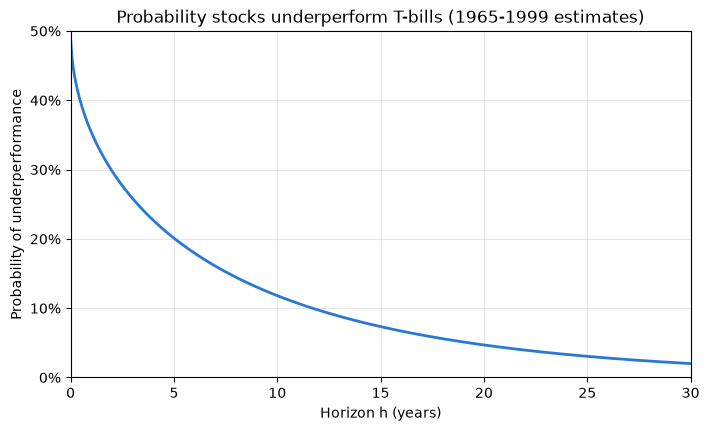

In [6]:
horizons = np.linspace(0.01, 30, 500)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(horizons, prob_under(horizons, sr), color="#2a78d6", lw=2)
ax.set_xlim(0, 30)
ax.set_ylim(0, 0.5)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Horizon h (years)")
ax.set_ylabel("Probability of underperformance")
ax.set_title("Probability stocks underperform T-bills (1965-1999 estimates)")
ax.grid(alpha=0.3)
plt.show()

_Answer:_ The probability falls quickly at first and then flattens out. It starts near 50% for a really short horizon, is about 35% at 1 year and about 12% at 10 years, and then slowly works its way down to 2% at 30 years. It never actually gets to zero. This all assumes the 1965-1999 mean and vol hold going forward and that returns are iid, which is a big assumption, especially for the mean since it's estimated with a lot of error.

## 3. Full Sample Analysis

Use the sample 1965-2025 to reconsider the 30-year probability. As of the end of 2025, calculate the probability of the stock return underperforming the risk-free rate over the next 30 years. That is, $R^m_{t,t+h}$ underperforming $R^f_{t,t+h}$ for $0<h\le 30$.

In [7]:
mu_new, sigma_new, sr_new = log_sharpe("1965", "2025")
print(f"mean = {mu_new:.2%}, vol = {sigma_new:.2%}, Sharpe = {sr_new:.4f}")
print(f"30-year probability: {prob_under(30, sr_new):.4%}")

mean = 5.82%, vol = 15.11%, Sharpe = 0.3852
30-year probability: 1.7444%


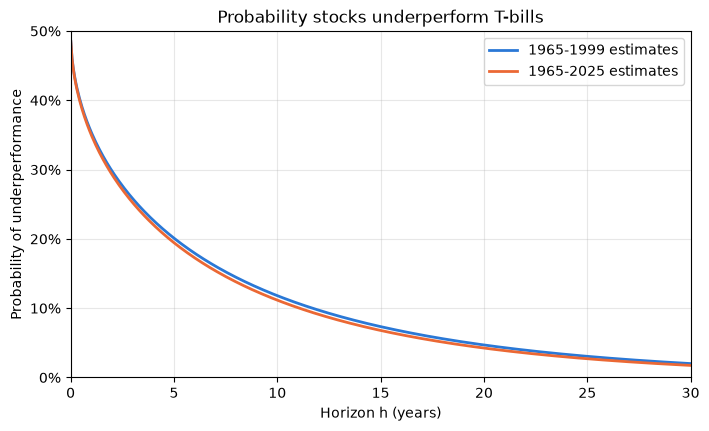

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(horizons, prob_under(horizons, sr), color="#2a78d6", lw=2, label="1965-1999 estimates")
ax.plot(horizons, prob_under(horizons, sr_new), color="#eb6834", lw=2, label="1965-2025 estimates")
ax.set_xlim(0, 30)
ax.set_ylim(0, 0.5)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Horizon h (years)")
ax.set_ylabel("Probability of underperformance")
ax.set_title("Probability stocks underperform T-bills")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

_Answer:_ Adding 2000-2025 to the sample pushes the log excess Sharpe ratio up slightly, from 0.375 to 0.385 (mean of 5.82%, vol of 15.11%). So as of the end of 2025, the estimated probability of stocks underperforming T-bills over the next 30 years is 1.74%, a little lower than the 2.01% from the 1999 estimates. The two curves are almost on top of each other. Even with the dot-com crash and 2008 in there, the equity premium over 2000-2025 ended up about the same as (actually a bit above) 1965-1999, so the overall picture doesn't really change.

## 4. In-Sample Estimate of Out-of-Sample Likelihood

Let's consider how things turned out relative to Barnstable's 1999 expectations.

What was the probability (based on the 1999 estimate of $\mu$) that the `h`-year market return, $R^m_{t,t+h}$, would be smaller than that realized in `2000-2025`?

**Hint**: You can calculate this as:

$$p = \Phi_{\mathcal{N}}\left(\sqrt{h}\; \frac{\bar{\texttt{r}}_{out-of-sample} - \bar{\texttt{r}}_{\text{in-sample}}}{\sigma_{\text{in-sample}}}\right)$$

where "in-sample" denotes 1965-1999 and "out-of-sample" denotes 2000-2025 ($h=26$ years).

In [9]:
h = 26

def oos_prob(col):
    in_sample = rets.loc["1965":"1999", col]
    out_sample = rets.loc["2000":"2025", col]
    mu_in, sigma_in = in_sample.mean() * 12, in_sample.std() * np.sqrt(12)
    mu_out = out_sample.mean() * 12
    p = norm.cdf(np.sqrt(h) * (mu_out - mu_in) / sigma_in)
    print(f"{col}: in-sample mean = {mu_in:.2%}, out-of-sample mean = {mu_out:.2%}, "
          f"in-sample vol = {sigma_in:.2%}, probability = {p:.2%}")

oos_prob("log r^m")

log r^m: in-sample mean = 11.76%, out-of-sample mean = 7.90%, in-sample vol = 14.96%, probability = 9.43%


_Answer:_ Based on 1965-1999, Barnstable would have expected an average log market return of about 11.76% a year, but 2000-2025 only delivered 7.90%. Using the 1999 vol of 14.96% and $h = 26$, the chance of a 26-year market return this low or lower was only about 9.4%. So from Barnstable's 1999 point of view, the next 26 years were a pretty bad draw.

In [10]:
# same thing with log excess returns
oos_prob("log r~^m")

log r~^m: in-sample mean = 5.63%, out-of-sample mean = 6.08%, in-sample vol = 15.03%, probability = 56.05%


_Answer:_ Most of that is the risk-free rate falling, though, not stocks doing badly relative to T-bills. Redoing the calculation with log excess returns, the 2000-2025 average (6.08%) is actually a bit above 1965-1999 (5.63%), and the probability comes out to about 56%, which is a completely normal outcome. Also, even with the weak total return, the 7.90% average log market return was still above the 6% hurdle used in the trust and put proposals.